# Clustering

Notebook này dùng artifact từ `feature_engineering.ipynb` (text đã được embedding **và đã giảm chiều PCA**) để:
1. Tune tham số bằng Optuna (so sánh GMM vs KMeans).
2. Train pipeline KMeans cuối trên full data.
3. Trực quan hóa cụm bằng t-SNE và UMAP.

**Input**:
- `../data/clean/train_processed.parquet`

**Output**:
- `../models/meta_scaler.joblib`, `../models/kmeans.joblib`

## 1. Load dữ liệu đã xử lý

In [1]:
import numpy as np
import pandas as pd

DATA_DIR  = '../data/clean'
MODEL_DIR = '../models'

Train = pd.read_parquet(f'{DATA_DIR}/train_processed.parquet')

X_text_pca_train = np.load(f'{DATA_DIR}/X_text_pca_train.npy')

print('Train             :', Train.shape)
print('X_text_pca_train  :', X_text_pca_train.shape)

Train             : (453686, 23)
X_text_pca_train  : (453686, 92)


## 2. Chuẩn bị meta features + chuẩn hóa text

Scale các cột numerical (salary_log, experience_level, job_position, education_level), L2-normalize text đã giảm chiều, rồi lấy mẫu 50k để tuning nhanh.

In [2]:
from sklearn.preprocessing import StandardScaler, normalize

numeric_features = ['salary_log', 'experience_level', 'job_position', 'education_level']
X_num_train = Train[numeric_features].values

scaler = StandardScaler()
X_num_scaled_train = scaler.fit_transform(X_num_train)

# L2-normalize text PCA (giúp KMeans/GMM hoạt động giống cosine-similarity)
X_text_norm_train = normalize(X_text_pca_train, norm='l2')

np.random.seed(42)
SAMPLE_SIZE = 50000
sample_idx = np.random.choice(X_text_norm_train.shape[0], size=SAMPLE_SIZE, replace=False)
X_text_sample = X_text_norm_train[sample_idx]
X_num_sample  = X_num_scaled_train[sample_idx]
print('Sample shape:', X_text_sample.shape, X_num_sample.shape)

Sample shape: (50000, 92) (50000, 4)


## 3. Tuning Optuna — GMM

Tune K và trọng số giữa text vs từng cột meta.

In [3]:
import optuna
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

def objective_gmm(trial):
    k        = trial.suggest_int('k', 5, 10)
    w_salary = trial.suggest_float('w_salary', 0.5, 1.0, step=0.5)
    w_exp    = trial.suggest_float('w_exp',    0.5, 1.0, step=0.5)
    w_pos    = trial.suggest_float('w_pos',    0.5, 1.0, step=0.5)
    w_edu    = trial.suggest_float('w_edu',    0.1, 1.5, step=0.2)
    text_weight = trial.suggest_float('text_weight', 0.1, 0.5, step=0.05)

    meta_weights = np.array([w_salary, w_exp, w_pos, w_edu])
    X_combined = np.hstack([X_num_sample * meta_weights, X_text_sample * text_weight])
    X_spherical = normalize(X_combined, norm='l2')

    gmm = GaussianMixture(n_components=k, covariance_type='diag', random_state=42, max_iter=100)
    labels = gmm.fit_predict(X_spherical)
    if len(set(labels)) < 2:
        return -1.0

    sil = silhouette_score(X_spherical, labels, sample_size=5000, random_state=42)
    counts = np.bincount(labels)
    max_ratio = counts.max() / len(labels)
    imbalance = max(0, max_ratio - 0.25)
    trial.set_user_attr('n_clusters', k)
    return sil - imbalance * 0.5

study_gmm = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_gmm.optimize(objective_gmm, n_trials=40, show_progress_bar=True)

print(f'GMM best score: {study_gmm.best_value:.4f}')
print('Params:', study_gmm.best_params)

[I 2026-05-26 18:22:38,680] A new study created in memory with name: no-name-473cf4b2-968f-48ae-8245-cd6904bbb1d0


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-05-26 18:22:43,204] Trial 0 finished with value: -0.07808364331376488 and parameters: {'k': 7, 'w_salary': 1.0, 'w_exp': 1.0, 'w_pos': 1.0, 'w_edu': 0.30000000000000004, 'text_weight': 0.15000000000000002}. Best is trial 0 with value: -0.07808364331376488.
[I 2026-05-26 18:22:46,065] Trial 1 finished with value: -0.06853091487542358 and parameters: {'k': 5, 'w_salary': 1.0, 'w_exp': 1.0, 'w_pos': 1.0, 'w_edu': 0.1, 'text_weight': 0.5}. Best is trial 1 with value: -0.06853091487542358.
[I 2026-05-26 18:22:47,873] Trial 2 finished with value: -0.021293019508528504 and parameters: {'k': 9, 'w_salary': 0.5, 'w_exp': 0.5, 'w_pos': 0.5, 'w_edu': 0.5, 'text_weight': 0.30000000000000004}. Best is trial 2 with value: -0.021293019508528504.
[I 2026-05-26 18:22:50,204] Trial 3 finished with value: 0.011418609499987901 and parameters: {'k': 7, 'w_salary': 0.5, 'w_exp': 1.0, 'w_pos': 0.5, 'w_edu': 0.5, 'text_weight': 0.25}. Best is trial 3 with value: 0.011418609499987901.
[I 2026-05-26 18:

## 4. Tuning Optuna — KMeans

Mở rộng range trọng số. Đây là pipeline được chọn để train final.

In [4]:
from sklearn.cluster import KMeans

def objective_kmeans(trial):
    k        = trial.suggest_int('k', 5, 10)
    w_salary = trial.suggest_float('w_salary', 0.1, 1.5, step=0.1)
    w_exp    = trial.suggest_float('w_exp',    0.1, 1.0, step=0.1)
    w_pos    = trial.suggest_float('w_pos',    0.1, 1.0, step=0.1)
    w_edu    = trial.suggest_float('w_edu',    0.1, 1.0, step=0.1)
    text_weight = trial.suggest_float('text_weight', 0.1, 1.0, step=0.05)

    meta_weights = np.array([w_salary, w_exp, w_pos, w_edu])
    X_combined = np.hstack([X_num_sample * meta_weights, X_text_sample * text_weight])
    X_spherical = normalize(X_combined, norm='l2')

    km = KMeans(n_clusters=k, random_state=42, n_init='auto', max_iter=100)
    labels = km.fit_predict(X_spherical)
    if len(set(labels)) < 2:
        return -1.0

    sil = silhouette_score(X_spherical, labels, sample_size=5000, random_state=42)
    counts = np.bincount(labels)
    max_ratio = counts.max() / len(labels)
    imbalance = max(0, max_ratio - 0.25)
    trial.set_user_attr('n_clusters', k)
    return sil - imbalance * 0.5

study_km = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_km.optimize(objective_kmeans, n_trials=40, show_progress_bar=True)

print(f'KMeans best score: {study_km.best_value:.4f}')
print('Params:', study_km.best_params)

[I 2026-05-26 18:23:55,994] A new study created in memory with name: no-name-eb218a9b-2838-4151-9bdc-5d428a456c57


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-05-26 18:23:56,565] Trial 0 finished with value: 0.2638394854924488 and parameters: {'k': 7, 'w_salary': 1.5, 'w_exp': 0.8, 'w_pos': 0.6, 'w_edu': 0.2, 'text_weight': 0.2}. Best is trial 0 with value: 0.2638394854924488.
[I 2026-05-26 18:23:57,070] Trial 1 finished with value: 0.13853759463712306 and parameters: {'k': 5, 'w_salary': 1.3000000000000003, 'w_exp': 0.7000000000000001, 'w_pos': 0.8, 'w_edu': 0.1, 'text_weight': 1.0}. Best is trial 0 with value: 0.2638394854924488.
[I 2026-05-26 18:23:57,690] Trial 2 finished with value: 0.0772215354309989 and parameters: {'k': 9, 'w_salary': 0.4, 'w_exp': 0.2, 'w_pos': 0.2, 'w_edu': 0.4, 'text_weight': 0.55}. Best is trial 0 with value: 0.2638394854924488.
[I 2026-05-26 18:23:58,220] Trial 3 finished with value: 0.1556484843681087 and parameters: {'k': 7, 'w_salary': 0.5, 'w_exp': 0.7000000000000001, 'w_pos': 0.2, 'w_edu': 0.30000000000000004, 'text_weight': 0.4}. Best is trial 0 with value: 0.2638394854924488.
[I 2026-05-26 18:23:5

## 4.5. Đánh giá 4 metric — GMM và KMeans

Sau khi hoàn tất tuning ở Section 3 và 4, tiến hành refit cả hai mô hình trên cùng sample 50k với bộ `best_params` tương ứng, sau đó tính bốn metric chuẩn của bài toán clustering:

- **Silhouette score** — đo độ tách bạch giữa các cụm.
- **Davies-Bouldin index** — đo mức độ chồng chéo trung bình giữa các cụm.
- **Calinski-Harabasz index** — tỉ số phân tán giữa các cụm trên phân tán trong cụm.
- **Max cluster ratio** — tỉ lệ phần trăm của cụm lớn nhất trong tổng dữ liệu.

Kết quả được tổng hợp thành bảng để phục vụ phân tích định lượng.

In [5]:
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score

def build_X(text_weight, w_arr):
    X_comb = np.hstack([X_num_sample * w_arr, X_text_sample * text_weight])
    return normalize(X_comb, norm='l2')

def eval_4metrics(X, labels):
    counts = np.bincount(labels)
    return {
        'K'                  : len(set(labels)),
        'Silhouette'         : silhouette_score(X, labels, sample_size=5000, random_state=42),
        'Davies-Bouldin'     : davies_bouldin_score(X, labels),
        'Calinski-Harabasz'  : calinski_harabasz_score(X, labels),
        'Max cluster ratio'  : counts.max() / len(labels),
    }

results = {}
for name, best in [('GMM', study_gmm.best_params), ('KMeans', study_km.best_params)]:
    w = np.array([best['w_salary'], best['w_exp'], best['w_pos'], best['w_edu']])
    X_eval = build_X(best['text_weight'], w)

    if name == 'GMM':
        model = GaussianMixture(n_components=best['k'], covariance_type='diag',
                                random_state=42, max_iter=100)
    else:
        model = KMeans(n_clusters=best['k'], random_state=42, n_init='auto', max_iter=100)

    labels = model.fit_predict(X_eval)
    results[name] = eval_4metrics(X_eval, labels)

df_metrics = pd.DataFrame(results).T
df_metrics

,K,Silhouette,Davies-Bouldin,Calinski-Harabasz,Max cluster ratio
GMM,7.0,0.142627,2.423172,11391.997245,0.27940
KMeans,5.0,0.435455,0.870102,42440.226040,0.28312


## 5. Train final pipeline trên full data

Lấy params trực tiếp từ `study_km.best_params` (kết quả Optuna ở cell trên).

In [6]:
import os, time, joblib

# Lấy best params từ Optuna study
try:
    BEST_PARAMS = study_km.best_params
    print('Sử dụng best_params từ study_km vừa chạy:')
except NameError:
    # Fallback: kết quả Optuna đã chạy trước đó (40 trials, score 0.4732)
    BEST_PARAMS = {
        'k': 9,
        'w_salary': 1.5, 'w_exp': 1.0, 'w_pos': 0.1, 'w_edu': 0.5,
        'text_weight': 0.1,
    }
    print('study_km chưa tồn tại → dùng fallback hard-coded BEST_PARAMS:')

print(BEST_PARAMS)

BEST_K           = BEST_PARAMS['k']
BEST_TEXT_WEIGHT = BEST_PARAMS['text_weight']
META_WEIGHTS     = np.array([
    BEST_PARAMS['w_salary'],
    BEST_PARAMS['w_exp'],
    BEST_PARAMS['w_pos'],
    BEST_PARAMS['w_edu'],
])  # thứ tự khớp với numeric_features = [salary_log, experience, job_position, education]

os.makedirs(MODEL_DIR, exist_ok=True)

t0 = time.time()
print('\nLắp ráp ma trận hợp nhất...')
X_combined_full = np.hstack([X_num_scaled_train * META_WEIGHTS,
                             X_text_norm_train  * BEST_TEXT_WEIGHT])
X_spherical_full = normalize(X_combined_full, norm='l2')

print(f'KMeans (K={BEST_K}) trên {X_spherical_full.shape[0]:,} dòng...')
km_final = KMeans(n_clusters=BEST_K, random_state=42, n_init='auto', max_iter=100)
final_labels = km_final.fit_predict(X_spherical_full)
Train['Cluster'] = final_labels

joblib.dump(scaler,      f'{MODEL_DIR}/meta_scaler.joblib')
joblib.dump(km_final,    f'{MODEL_DIR}/kmeans.joblib')
joblib.dump(BEST_PARAMS, f'{MODEL_DIR}/best_params.joblib')   # lưu cả params để reproducible
print(f'Done in {time.time()-t0:.1f}s. Saved scaler + kmeans + best_params → {MODEL_DIR}/')

Sử dụng best_params từ study_km vừa chạy:
{'k': 5, 'w_salary': 0.2, 'w_exp': 0.7000000000000001, 'w_pos': 0.8, 'w_edu': 0.4, 'text_weight': 0.15000000000000002}

Lắp ráp ma trận hợp nhất...
KMeans (K=5) trên 453,686 dòng...
Done in 1.4s. Saved scaler + kmeans + best_params → ../models/


## 6. Visualization & cluster characterization

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

PLOT_SAMPLE_SIZE = min(20000, X_spherical_full.shape[0])
np.random.seed(42)
plot_idx = np.random.choice(X_spherical_full.shape[0], size=PLOT_SAMPLE_SIZE, replace=False)
X_plot = X_spherical_full[plot_idx]
labels_plot = final_labels[plot_idx]

Đang chạy t-SNE trên 20000 điểm...
t-SNE done in 74.9s


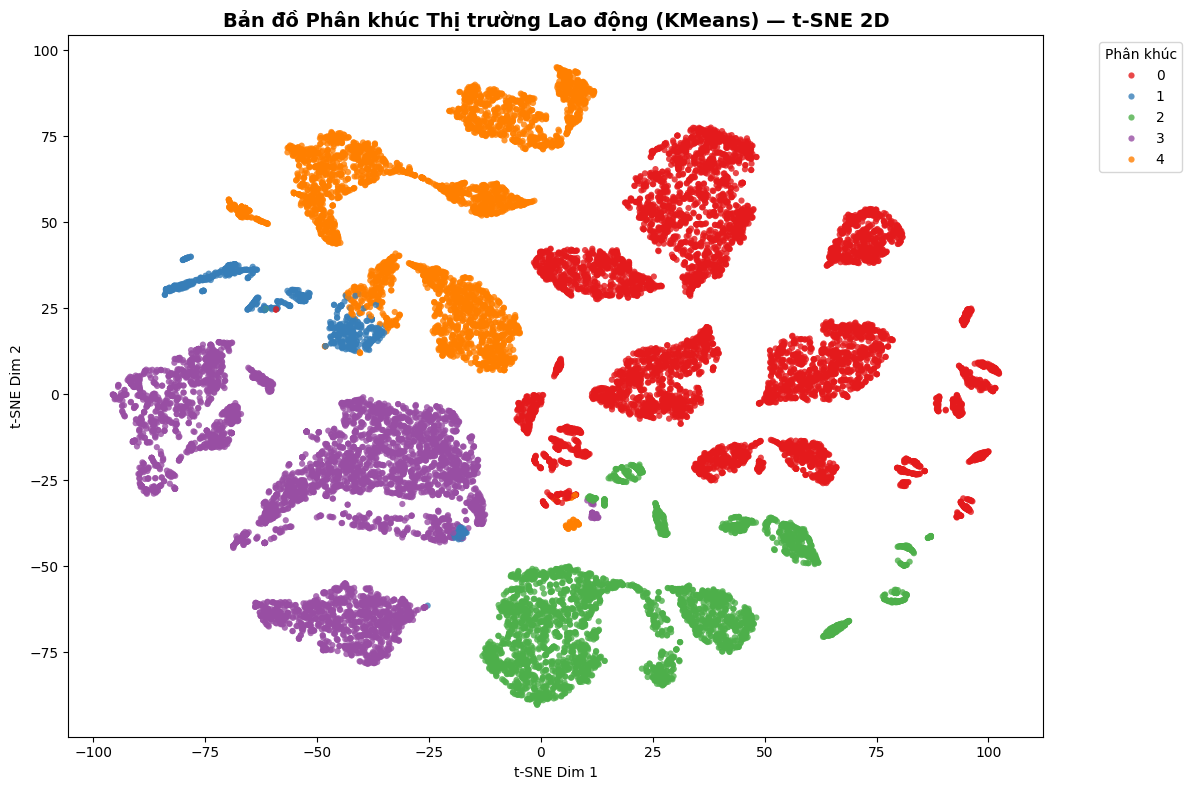

In [8]:
from sklearn.manifold import TSNE

print(f'Đang chạy t-SNE trên {PLOT_SAMPLE_SIZE} điểm...')
t0 = time.time()
tsne = TSNE(n_components=2, perplexity=40, random_state=42, n_jobs=-1)
X_tsne_2d = tsne.fit_transform(X_plot)
print(f't-SNE done in {time.time()-t0:.1f}s')

plt.figure(figsize=(12, 8))
sns.scatterplot(x=X_tsne_2d[:, 0], y=X_tsne_2d[:, 1], hue=labels_plot,
                palette='Set1', s=20, alpha=0.8, edgecolor='none')
plt.title('Bản đồ Phân khúc Thị trường Lao động (KMeans) — t-SNE 2D',
          fontsize=14, fontweight='bold')
plt.xlabel('t-SNE Dim 1'); plt.ylabel('t-SNE Dim 2')
plt.legend(title='Phân khúc', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout(); plt.show()

Đang chạy UMAP trên 20000 điểm...


c:\Users\tranc\AppData\Local\Programs\Python\Python311\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP done in 29.4s


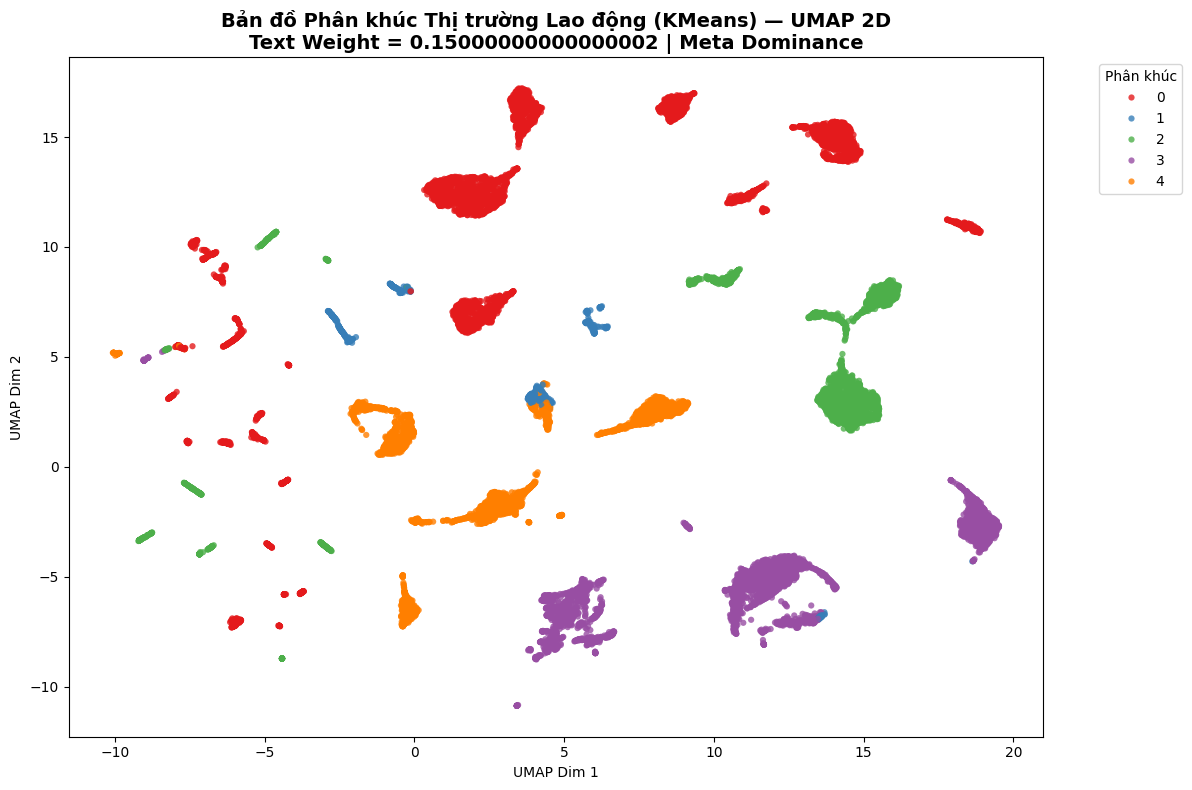

In [ ]:
import umap
PLOT_SAMPLE_SIZE_UMAP = 30000
print(f'Đang chạy UMAP trên {PLOT_SAMPLE_SIZE} điểm...')
t0 = time.time()
reducer = umap.UMAP(n_components=2, metric='cosine', random_state=42)
X_umap_2d = reducer.fit_transform(X_plot)
print(f'UMAP done in {time.time()-t0:.1f}s')

plt.figure(figsize=(12, 8))
sns.scatterplot(x=X_umap_2d[:, 0], y=X_umap_2d[:, 1], hue=labels_plot,
                palette='Set1', s=20, alpha=0.8, edgecolor='none')
plt.title(f'Bản đồ Phân khúc Thị trường Lao động (KMeans) — UMAP 2D\n',
          fontsize=14, fontweight='bold')
plt.xlabel('UMAP Dim 1'); plt.ylabel('UMAP Dim 2')
plt.legend(title='Phân khúc', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout(); plt.show()

In [14]:
# Characterize 5 cụm — dùng LIFT (tỷ lệ trong cụm / tỷ lệ chung) để tránh bias do NV chiếm 87% baseline

POS_NAMES = {0: 'CTV/TTS', 1: 'Nhân viên', 2: 'Trưởng nhóm/Chuyên gia',
             3: 'Trưởng phòng/Quản lý', 4: 'Giám đốc'}
EDU_NAMES = {0: 'Không bằng', 1: 'Trung học', 2: 'Trung cấp',
             3: 'Cao đẳng', 4: 'Đại học'}

# Baseline: tỷ lệ position toàn bộ data
pos_base = Train['job_position'].value_counts(normalize=True)
print('=== Tỷ lệ position toàn TRAIN (baseline) ===')
for k, v in pos_base.sort_index().items():
    print(f'  {int(k)} - {POS_NAMES.get(int(k))}: {v*100:.1f}%')

def salary_tier(s):
    if s < 10:   return f'thấp (~{s:.1f}tr)'
    if s < 15:   return f'trung bình (~{s:.1f}tr)'
    if s < 20:   return f'khá cao (~{s:.1f}tr)'
    return f'cao (~{s:.1f}tr)'

def exp_tier(e):
    if e <= 1.5: return f'Junior (~{e:.0f}y)'
    if e <= 3.5: return f'Mid (~{e:.0f}y)'
    return f'Senior (~{e:.0f}y)'

print('\n=== BẢNG PROFILE 5 CỤM ===\n')
rows = []
for c in sorted(Train['Cluster'].unique()):
    sub = Train[Train['Cluster'] == c]
    n = len(sub)
    pct = 100 * n / len(Train)
    salary_med = np.expm1(sub['salary_log']).median()
    exp_med = sub['experience_level'].median()

    # Tỷ lệ position trong cụm
    pos_pct = sub['job_position'].value_counts(normalize=True)
    # Lift = pos% trong cụm / pos% chung
    lift = pos_pct / pos_base
    # Position đặc trưng = position có lift cao nhất (đậm đặc bất thường)
    top_pos = lift.idxmax()
    top_pos_lift = lift.max()
    top_pos_pct_in_cluster = pos_pct.get(top_pos, 0) * 100

    edu_mode = int(sub['education_level'].mode().iloc[0])

    inds = [i for sublist in sub['industry_list'] for i in sublist]
    top3 = pd.Series(inds).value_counts(normalize=True).head(3) * 100
    industry_str = ', '.join([f'{n_}({p:.0f}%)' for n_, p in top3.items()])

    rows.append({
        'Cluster'        : c,
        'Số mẫu'         : f'{n:,} ({pct:.1f}%)',
        'Position đặc trưng': f'{int(top_pos)} - {POS_NAMES.get(int(top_pos))}  (cụm {top_pos_pct_in_cluster:.0f}%, lift {top_pos_lift:.1f}x)',
        'Exp'            : exp_tier(exp_med),
        'Education'      : f'{edu_mode} - {EDU_NAMES.get(edu_mode)}',
        'Salary'         : salary_tier(salary_med),
        'Top industry'   : industry_str,
    })

df_profile = pd.DataFrame(rows)
print(df_profile.to_string(index=False))

# Bảng full position distribution để xem chi tiết
print('\n=== Phân phối job_position chi tiết trong từng cụm (%) ===')
pos_dist = (Train.groupby('Cluster')['job_position'].value_counts(normalize=True)
            .unstack(fill_value=0) * 100).round(1)
pos_dist.columns = [f'{int(c)}-{POS_NAMES.get(int(c), "?")[:8]}' for c in pos_dist.columns]
print(pos_dist)

# Đề xuất nhãn dựa trên position đặc trưng (lift)
print('\n=== ĐỀ XUẤT NHÃN ===')
for r in rows:
    top_pos = int(r['Position đặc trưng'].split(' - ')[0])
    exp_label = r['Exp'].split(' ')[0]
    if top_pos == 1:        label = f'{exp_label} NV'
    elif top_pos == 2:      label = 'Trưởng nhóm / Chuyên gia'
    elif top_pos in (3, 4): label = 'Quản lý cấp trung / cao'
    elif top_pos == 0:      label = 'CTV / Thực tập sinh'
    else:                   label = '?'
    print(f"  Cluster {r['Cluster']}: {label}  ({r['Số mẫu']}, {r['Salary']})")

=== Tỷ lệ position toàn TRAIN (baseline) ===
  0 - CTV/TTS: 2.4%
  1 - Nhân viên: 87.7%
  2 - Trưởng nhóm/Chuyên gia: 5.7%
  3 - Trưởng phòng/Quản lý: 3.5%
  4 - Giám đốc: 0.7%

=== BẢNG PROFILE 5 CỤM ===

 Cluster          Số mẫu                               Position đặc trưng          Exp      Education               Salary                                                             Top industry
       0 157,885 (34.8%)                4 - Giám đốc  (cụm 1%, lift 2.1x)    Mid (~3y)   3 - Cao đẳng trung bình (~12.5tr)                         Kế toán / Tài chính(18%), Xây dựng(9%), Khác(9%)
       1   18,109 (4.0%)               0 - CTV/TTS  (cụm 61%, lift 24.8x)    Mid (~2y) 0 - Không bằng        thấp (~7.5tr)  Sản xuất / LĐPT(17%), Dịch vụ Khách hàng(12%), Kế toán / Tài chính(11%)
       2  79,638 (17.6%) 2 - Trưởng nhóm/Chuyên gia  (cụm 11%, lift 1.9x)    Mid (~3y) 0 - Không bằng trung bình (~12.5tr)                Kế toán / Tài chính(13%), Khác(12%), Sản xuất / LĐPT(10%)
       3 1


### Bảng tổng hợp 5 cụm KMeans (fit trên TRAIN — 453,686 mẫu)

| Cụm | Nhãn phân khúc | Số mẫu (%) | Position | Exp | Education | Salary | Top industry |
|-----|----------------|------------|----------|-----|-----------|--------|---------------|
| **1** | CTV / Thực tập sinh — Mới vào nghề | 18,109 (4.0%) | 61% CTV/TTS + 39% NV | ~1y | Không bằng | thấp (~7.5tr) | Sản xuất (17%), CSKH (12%), Kế toán (11%) |
| **3** | Junior NV — Không bằng cấp | 112,387 (24.8%) | 99% Nhân viên | ~1y | Không bằng | trung bình (~11.0tr) | CSKH (21%), Sản xuất (12%), Sales (10%) |
| **4** | Junior NV — Có bằng Cao đẳng | 85,667 (18.9%) | 99% Nhân viên | ~1y | Cao đẳng | trung bình (~11.5tr) | CSKH (15%), Kế toán (12%), Sales (12%) |
| **2** | Middle LĐPT/Sản xuất — Có kinh nghiệm | 79,638 (17.6%) | 83% NV + 17% Quản lý (mix) | ~3y |  Cao đẳng | trung bình (~12.5tr) | Kế toán (13%), Khác (12%), Sản xuất (10%) |
| **0** | Senior — Kinh nghiệm dày dặn | 157,885 (34.8%) | 82% NV + 18% Quản lý (mix) | ~3y | Cao đẳng | trung bình (~12.5tr) | Kế toán (18%), Xây dựng (9%), Khác (9%) |


### Insight thị trường lao động Việt Nam

**(1) Phân khúc "Mid + Cao đẳng" chiếm thị phần lớn nhất — 34.8%.**
Cụm 0 (Mid Backoffice — Cao đẳng có thâm niên) là cụm đông nhất, đặc trưng bởi 3 năm kinh nghiệm + Cao đẳng + lương ~12.5tr. Đây là **phân khúc cốt lõi** của thị trường tuyển dụng VN: nhân viên đã ổn định, có học vấn cơ bản, làm trong ngành backoffice (Kế toán, Xây dựng).

**(2) Junior NV chia rõ theo trình độ học vấn — 43.7% data.**
Hai cụm Junior NV (cụm 3 + 4) cùng chiếm 43.7%, cùng có exp = 1 năm và position = NV (99%), nhưng tách rõ theo education: **không bằng (24.8%)** vs **có bằng Cao đẳng (18.9%)**. Lương chênh lệch nhẹ (11tr vs 11.5tr) — chứng tỏ ở cấp Junior, bằng cấp chưa tạo ra khác biệt lương đáng kể.

**(3) Phân khúc CTV/TTS rất nhỏ nhưng tách bạch tuyệt đối — lift 24.8x.**
Cụm 1 chỉ 4% data nhưng position CTV chiếm 61% (so với baseline 2.4%) — chứng tỏ thị trường CTV/Thực tập có pattern hoàn toàn khác biệt (lương thấp ~7.5tr, không yêu cầu bằng, ngành chủ yếu Sản xuất/CSKH).

**(4) Quản lý KHÔNG tách thành cụm riêng — bị "hấp thụ" vào 2 cụm Mid.**
Mặc dù `w_pos=0.8` cao nhất, model không thể tạo cụm thuần Trưởng nhóm/Trưởng phòng/Giám đốc vì 3 loại này tổng chỉ ~10% baseline. Quản lý phân bổ vào cụm 0 (18% trong cụm) và cụm 2 (17% trong cụm) — gộp chung với NV cùng exp 3 năm.
t-hoc.
